# Exploratory Data Analysis (EDA) - URL Classification Dataset

This notebook performs exploratory data analysis on the URL classification dataset to understand the data distribution, patterns, and characteristics.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re
from urllib.parse import urlparse
import warnings
warnings.filterwarnings('ignore')

# Set style for plots
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

## 1. Data Loading and Basic Information

In [4]:
# Load the dataset
df = pd.read_csv('../data/raw/dataset.csv')

print(f"Dataset shape: {df.shape}")
print(f"\nColumn names: {list(df.columns)}")
print(f"\nFirst 5 rows:")
df.head()

Dataset shape: (651191, 2)

Column names: ['url', 'type']

First 5 rows:


,url,type
0,br-icloud.com.br,phishing
1,mp3raid.com/music/krizz_kaliko.html,benign
2,bopsecrets.org/rexroth/cr/1.htm,benign
3,http://www.garage-pirenne.be/index.php?option=...,defacement
4,http://adventure-nicaragua.net/index.php?optio...,defacement


In [5]:
# Basic dataset information
print("Dataset Info:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(f"Number of duplicates: {df.duplicated().sum()}")

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 651191 entries, 0 to 651190
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   url     651191 non-null  object
 1   type    651191 non-null  object
dtypes: object(2)
memory usage: 9.9+ MB

Missing values:
url     0
type    0
dtype: int64

Duplicate rows:
Number of duplicates: 10066


## 2. Target Variable Analysis

In [6]:
# Analyze target variable distribution
print("Class distribution:")
class_counts = df['type'].value_counts()
print(class_counts)
print(f"\nClass percentages:")
print(df['type'].value_counts(normalize=True) * 100)

Class distribution:
type
benign        428103
defacement     96457
phishing       94111
malware        32520
Name: count, dtype: int64

Class percentages:
type
benign        65.741541
defacement    14.812398
phishing      14.452135
malware        4.993927
Name: proportion, dtype: float64


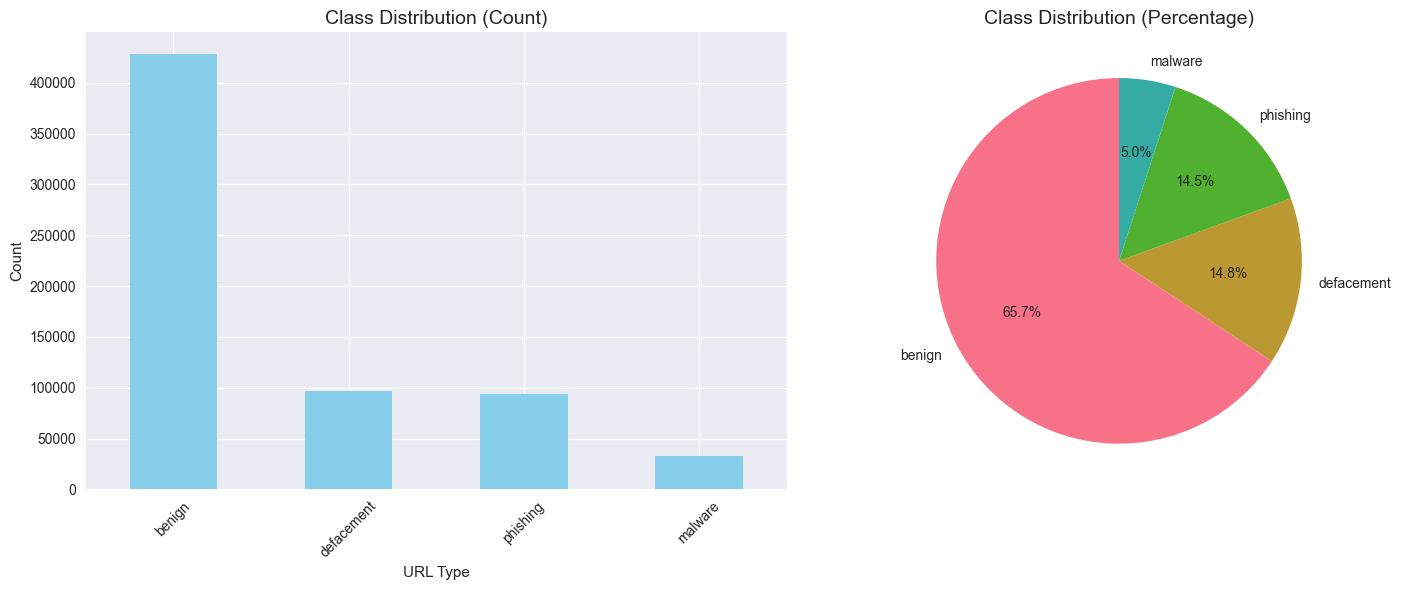

In [7]:
# Visualize class distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Bar plot
class_counts.plot(kind='bar', ax=ax1, color='skyblue')
ax1.set_title('Class Distribution (Count)', fontsize=14)
ax1.set_xlabel('URL Type')
ax1.set_ylabel('Count')
ax1.tick_params(axis='x', rotation=45)

# Pie chart
ax2.pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%', startangle=90)
ax2.set_title('Class Distribution (Percentage)', fontsize=14)

plt.tight_layout()
plt.show()

## 3. URL Length Analysis

In [8]:
# Calculate URL lengths
df['url_length'] = df['url'].str.len()

print("URL Length Statistics:")
print(df['url_length'].describe())

print("\nURL Length by Class:")
print(df.groupby('type')['url_length'].describe())

URL Length Statistics:
count    651191.000000
mean         60.156831
std          44.753902
min           1.000000
25%          32.000000
50%          47.000000
75%          77.000000
max        2175.000000
Name: url_length, dtype: float64

URL Length by Class:
               count       mean        std   min   25%   50%    75%     max
type                                                                       
benign      428103.0  57.675429  44.301093   6.0  31.0  46.0   71.0  2175.0
defacement   96457.0  86.339395  41.885123  17.0  55.0  81.0  105.0   327.0
malware      32520.0  56.542958  28.441223   7.0  33.0  49.0   76.0   378.0
phishing     94111.0  45.858051  43.750813   1.0  25.0  35.0   49.0  1779.0


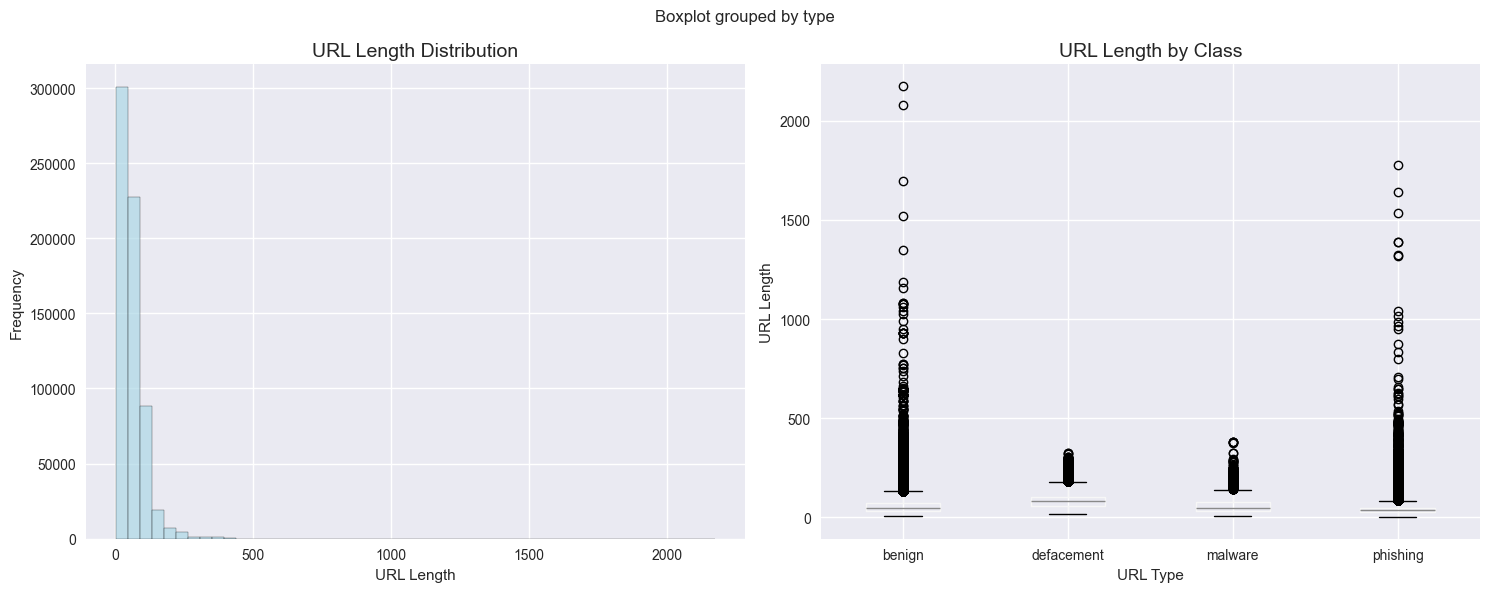

In [9]:
# Visualize URL length distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Overall distribution
ax1.hist(df['url_length'], bins=50, alpha=0.7, color='lightblue', edgecolor='black')
ax1.set_title('URL Length Distribution', fontsize=14)
ax1.set_xlabel('URL Length')
ax1.set_ylabel('Frequency')

# Box plot by class
df.boxplot(column='url_length', by='type', ax=ax2)
ax2.set_title('URL Length by Class', fontsize=14)
ax2.set_xlabel('URL Type')
ax2.set_ylabel('URL Length')

plt.tight_layout()
plt.show()

## 4. URL Structure Analysis

In [10]:
# Extract URL components
def extract_url_features(url):
    try:
        parsed = urlparse(url if url.startswith(('http://', 'https://')) else 'http://' + url)
        return {
            'scheme': parsed.scheme,
            'domain': parsed.netloc,
            'path': parsed.path,
            'query': parsed.query,
            'fragment': parsed.fragment
        }
    except:
        return {
            'scheme': '',
            'domain': '',
            'path': '',
            'query': '',
            'fragment': ''
        }

# Apply feature extraction to a sample (for performance)
sample_df = df.sample(n=min(10000, len(df)), random_state=42)
url_features = sample_df['url'].apply(extract_url_features)
url_features_df = pd.DataFrame(url_features.tolist())
sample_df = pd.concat([sample_df.reset_index(drop=True), url_features_df], axis=1)

URL Schemes:
scheme
http     9729
https     271
Name: count, dtype: int64


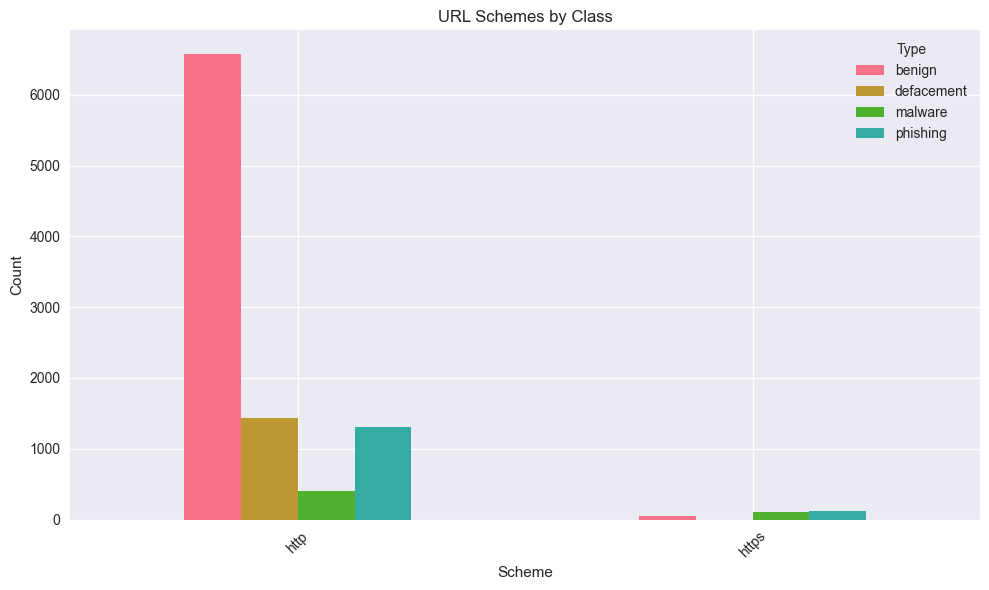

In [11]:
# Analyze URL schemes
print("URL Schemes:")
scheme_counts = sample_df['scheme'].value_counts()
print(scheme_counts)

# Visualize schemes by class
scheme_class = pd.crosstab(sample_df['scheme'], sample_df['type'])
scheme_class.plot(kind='bar', figsize=(10, 6))
plt.title('URL Schemes by Class')
plt.xlabel('Scheme')
plt.ylabel('Count')
plt.legend(title='Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. Special Characters and Patterns Analysis

In [12]:
# Count special characters in URLs
def count_special_chars(url):
    return {
        'dots': url.count('.'),
        'hyphens': url.count('-'),
        'underscores': url.count('_'),
        'slashes': url.count('/'),
        'question_marks': url.count('?'),
        'equals': url.count('='),
        'ampersands': url.count('&'),
        'digits': sum(c.isdigit() for c in url),
        'uppercase': sum(c.isupper() for c in url)
    }

# Apply to sample
special_chars = sample_df['url'].apply(count_special_chars)
special_chars_df = pd.DataFrame(special_chars.tolist())
sample_df = pd.concat([sample_df.reset_index(drop=True), special_chars_df], axis=1)

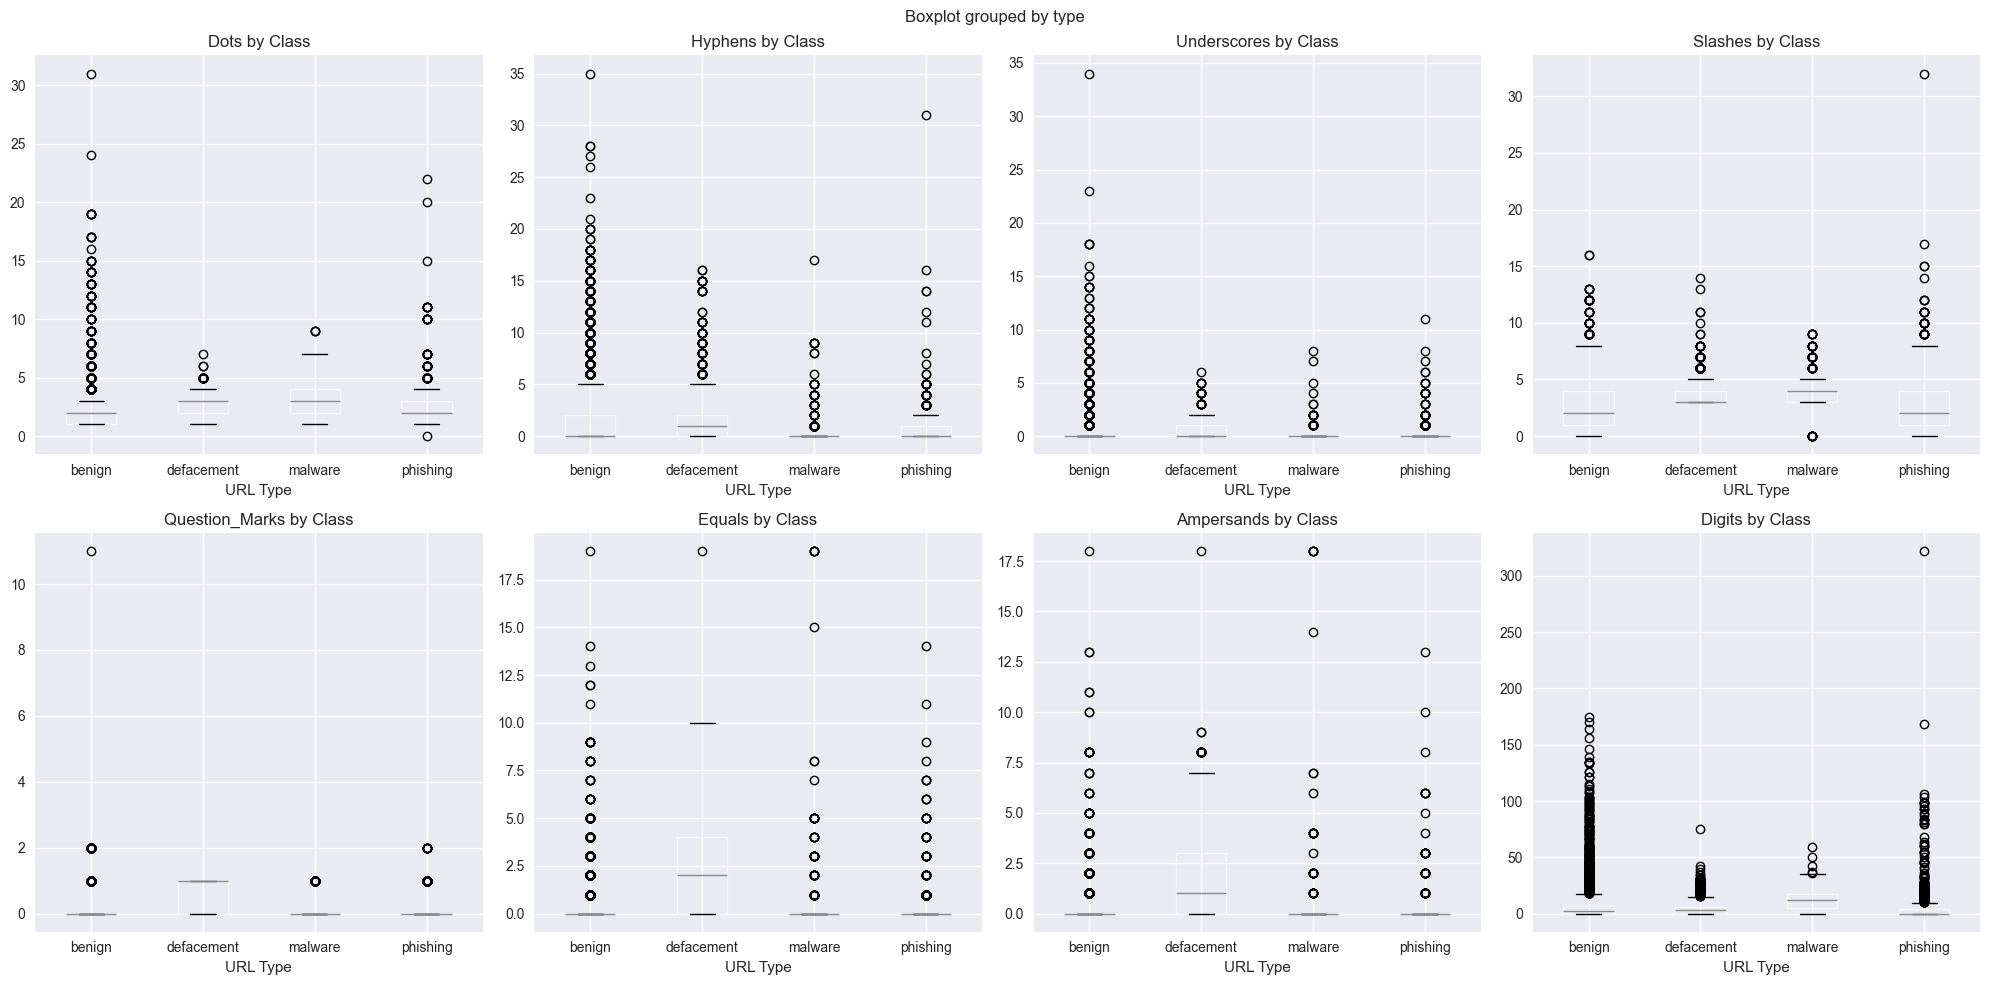

In [13]:
# Analyze special characters by class
special_char_cols = ['dots', 'hyphens', 'underscores', 'slashes', 'question_marks', 'equals', 'ampersands', 'digits']

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.ravel()

for i, col in enumerate(special_char_cols):
    sample_df.boxplot(column=col, by='type', ax=axes[i])
    axes[i].set_title(f'{col.title()} by Class')
    axes[i].set_xlabel('URL Type')

plt.tight_layout()
plt.show()

## 6. Domain Analysis

In [14]:
# Analyze domain characteristics
sample_df['domain_length'] = sample_df['domain'].str.len()
sample_df['subdomain_count'] = sample_df['domain'].str.count('\.') 

print("Domain Length Statistics by Class:")
print(sample_df.groupby('type')['domain_length'].describe())

print("\nSubdomain Count Statistics by Class:")
print(sample_df.groupby('type')['subdomain_count'].describe())

Domain Length Statistics by Class:
             count       mean        std  min   25%   50%   75%    max
type                                                                  
benign      6624.0  16.897494  13.613534  4.0  11.0  15.0  19.0  239.0
defacement  1435.0  19.144948   5.701908  7.0  15.0  19.0  23.0   49.0
malware      515.0  15.646602   6.008373  6.0  12.0  14.0  19.0   61.0
phishing    1426.0  19.587658  11.160442  4.0  14.0  17.0  21.0  227.0

Subdomain Count Statistics by Class:
             count      mean       std  min  25%  50%  75%   max
type                                                            
benign      6624.0  1.425272  1.142498  1.0  1.0  1.0  2.0  24.0
defacement  1435.0  1.877352  0.651366  1.0  1.0  2.0  2.0   4.0
malware      515.0  2.089320  0.958163  1.0  1.0  2.0  3.0   7.0
phishing    1426.0  1.997195  1.200581  0.0  1.0  2.0  2.0  11.0


Top 10 TLDs:
tld
com    6114
org     808
net     447
uk      197
ca      185
de      178
edu     150
br      123
it      106
au      104
Name: count, dtype: int64


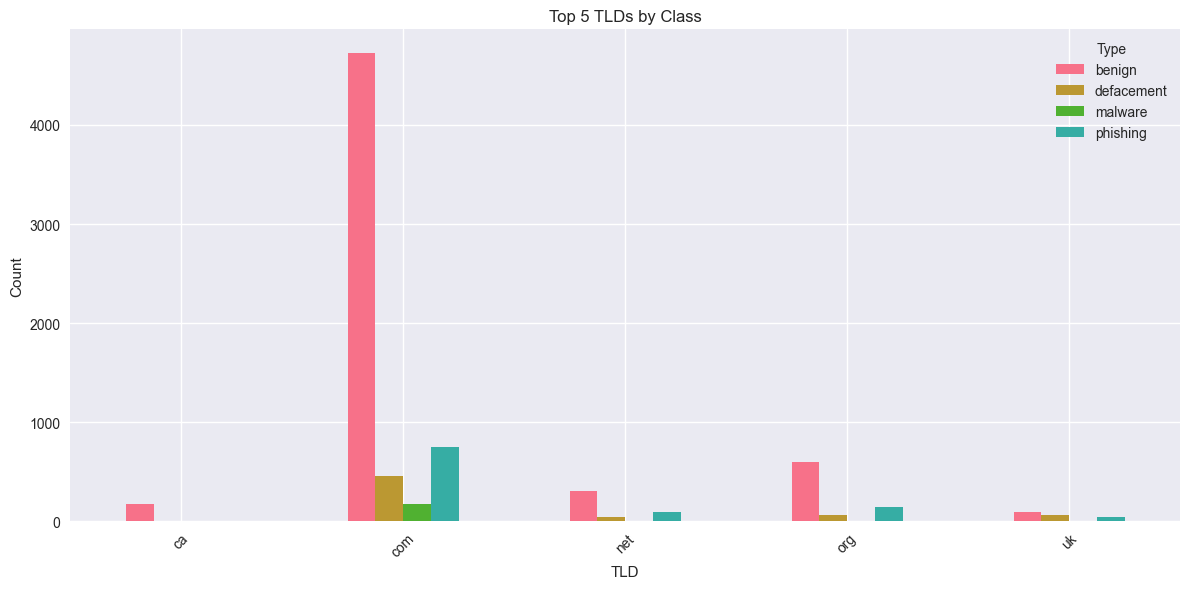

In [15]:
# Top-level domains analysis
def extract_tld(domain):
    if domain and '.' in domain:
        return domain.split('.')[-1]
    return 'unknown'

sample_df['tld'] = sample_df['domain'].apply(extract_tld)

print("Top 10 TLDs:")
tld_counts = sample_df['tld'].value_counts().head(10)
print(tld_counts)

# Visualize TLD distribution by class
top_tlds = tld_counts.index[:5]
tld_class = pd.crosstab(sample_df[sample_df['tld'].isin(top_tlds)]['tld'], 
                        sample_df[sample_df['tld'].isin(top_tlds)]['type'])

tld_class.plot(kind='bar', figsize=(12, 6))
plt.title('Top 5 TLDs by Class')
plt.xlabel('TLD')
plt.ylabel('Count')
plt.legend(title='Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Suspicious Patterns Analysis

In [16]:
# Check for suspicious patterns
def check_suspicious_patterns(url):
    patterns = {
        'has_ip': bool(re.search(r'\b(?:[0-9]{1,3}\.){3}[0-9]{1,3}\b', url)),
        'has_suspicious_tld': any(tld in url.lower() for tld in ['.tk', '.ml', '.ga', '.cf']),
        'has_url_shortener': any(short in url.lower() for short in ['bit.ly', 'tinyurl', 'goo.gl', 't.co']),
        'has_suspicious_keywords': any(word in url.lower() for word in ['login', 'secure', 'account', 'update', 'verify']),
        'has_multiple_subdomains': url.count('.') > 3,
        'has_port': ':' in url and any(char.isdigit() for char in url.split(':')[-1][:5]),
        'has_encoded_chars': '%' in url
    }
    return patterns

# Apply pattern checking
suspicious_patterns = sample_df['url'].apply(check_suspicious_patterns)
suspicious_df = pd.DataFrame(suspicious_patterns.tolist())
sample_df = pd.concat([sample_df.reset_index(drop=True), suspicious_df], axis=1)

In [17]:
# Analyze suspicious patterns by class
pattern_cols = ['has_ip', 'has_suspicious_tld', 'has_url_shortener', 'has_suspicious_keywords', 
                'has_multiple_subdomains', 'has_port', 'has_encoded_chars']

pattern_analysis = {}
for col in pattern_cols:
    pattern_analysis[col] = sample_df.groupby('type')[col].mean()

pattern_df = pd.DataFrame(pattern_analysis).T
print("Suspicious Pattern Prevalence by Class (as percentage):")
print((pattern_df * 100).round(2))

Suspicious Pattern Prevalence by Class (as percentage):
type                     benign  defacement  malware  phishing
has_ip                     0.05        0.00    36.70      0.56
has_suspicious_tld         0.95        0.42     0.19      2.17
has_url_shortener          5.87        2.09     1.94      7.29
has_suspicious_keywords    5.03        0.91     0.78      9.75
has_multiple_subdomains    6.37       17.84    36.50     11.57
has_port                   0.35        1.67    49.71      1.75
has_encoded_chars          4.65        1.25    13.79      1.54


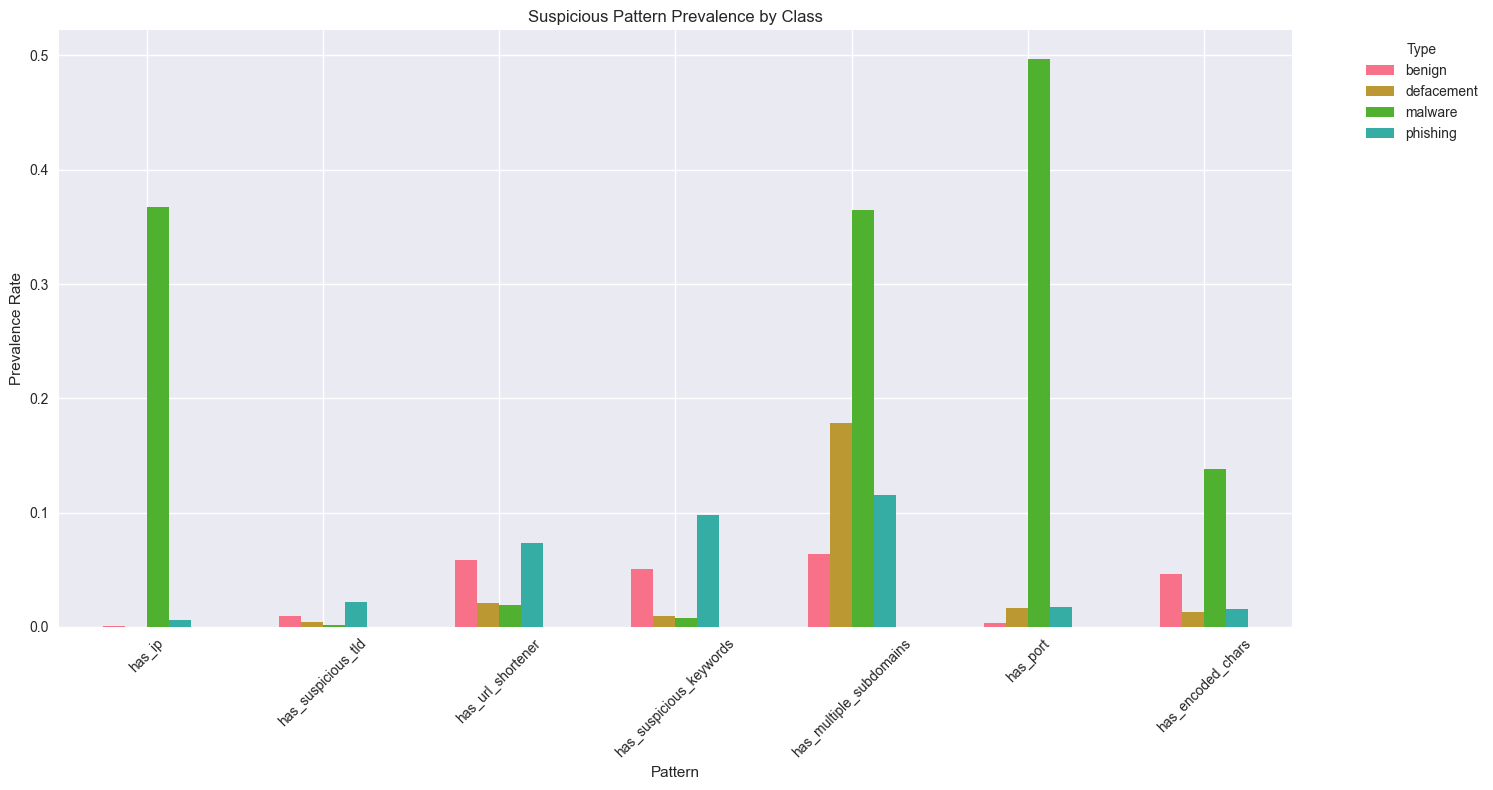

In [18]:
# Visualize suspicious patterns
pattern_df.plot(kind='bar', figsize=(15, 8))
plt.title('Suspicious Pattern Prevalence by Class')
plt.xlabel('Pattern')
plt.ylabel('Prevalence Rate')
plt.legend(title='Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 8. Correlation Analysis

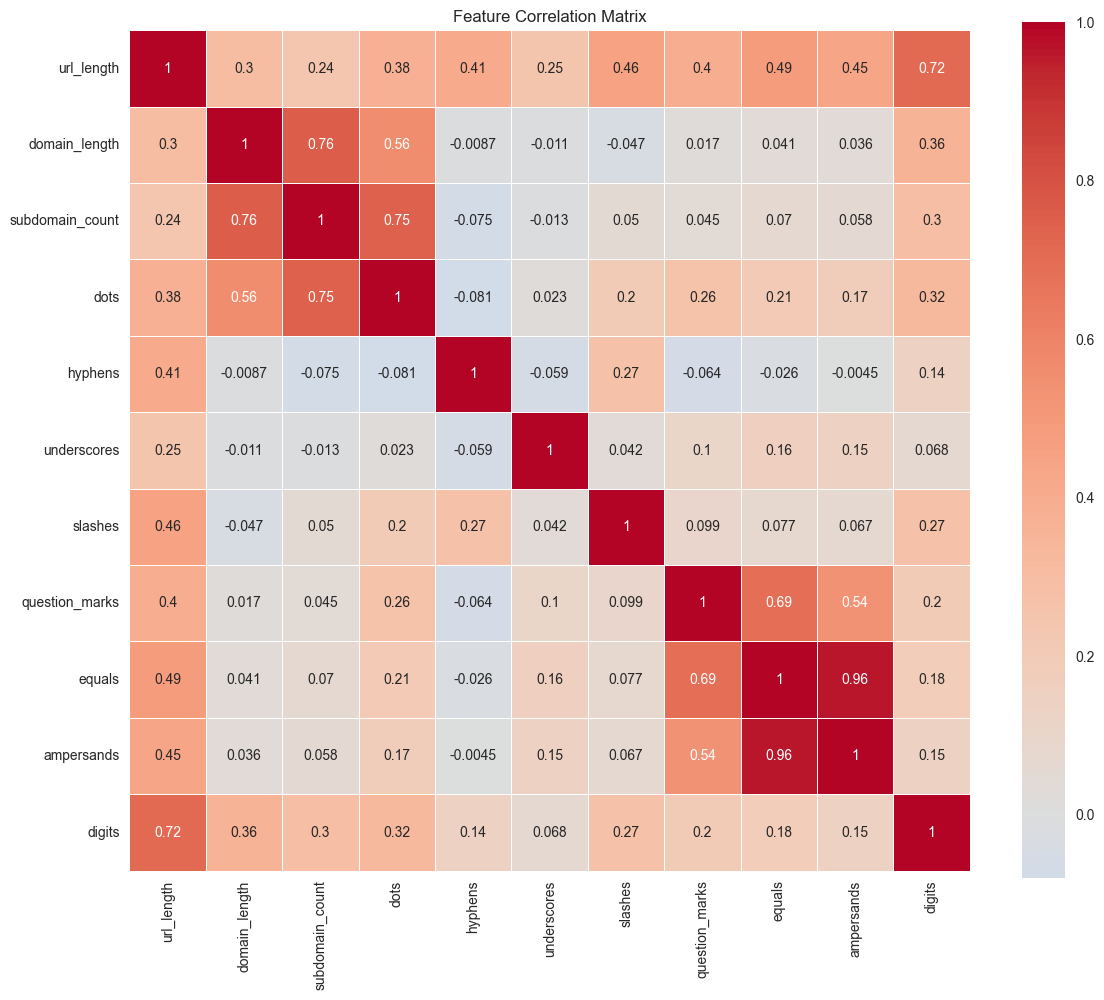

In [19]:
# Select numerical features for correlation analysis
numerical_features = ['url_length', 'domain_length', 'subdomain_count'] + special_char_cols
correlation_matrix = sample_df[numerical_features].corr()

# Plot correlation heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, 
            square=True, linewidths=0.5)
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

## 9. Key Findings Summary

In [20]:
print("=== KEY FINDINGS FROM EDA ===")
print(f"\n1. Dataset Overview:")
print(f"   - Total samples: {len(df):,}")
print(f"   - Classes: {df['type'].nunique()} ({', '.join(df['type'].unique())})")
print(f"   - Missing values: {df.isnull().sum().sum()}")

print(f"\n2. Class Distribution:")
for class_name, count in df['type'].value_counts().items():
    percentage = (count / len(df)) * 100
    print(f"   - {class_name}: {count:,} ({percentage:.1f}%)")

print(f"\n3. URL Length Insights:")
print(f"   - Average URL length: {df['url_length'].mean():.1f} characters")
print(f"   - Longest URL: {df['url_length'].max()} characters")
print(f"   - Shortest URL: {df['url_length'].min()} characters")

print(f"\n4. Recommendations for Preprocessing:")
print(f"   - Extract URL structural features (length, domain, TLD, etc.)")
print(f"   - Count special characters and suspicious patterns")
print(f"   - Consider text-based features from URL content")
print(f"   - Handle class imbalance if present")
print(f"   - Feature scaling may be needed for numerical features")

=== KEY FINDINGS FROM EDA ===

1. Dataset Overview:
   - Total samples: 651,191
   - Classes: 4 (phishing, benign, defacement, malware)
   - Missing values: 0

2. Class Distribution:
   - benign: 428,103 (65.7%)
   - defacement: 96,457 (14.8%)
   - phishing: 94,111 (14.5%)
   - malware: 32,520 (5.0%)

3. URL Length Insights:
   - Average URL length: 60.2 characters
   - Longest URL: 2175 characters
   - Shortest URL: 1 characters

4. Recommendations for Preprocessing:
   - Extract URL structural features (length, domain, TLD, etc.)
   - Count special characters and suspicious patterns
   - Consider text-based features from URL content
   - Handle class imbalance if present
   - Feature scaling may be needed for numerical features
